# Coffin cavity (4Q): HFSS analysis

4-transmon coffin cavity with a shared readout cavity, 2 readout ports and 4 drive ports.
Geometry comes from `inventor_coffin_4q.py` (Inventor → `inventor_files/coffin_4Q.stp` + `coffin_4Q_params.json`).

Flow (same as `SNAIL_coffin_cavity.ipynb`): import STEP → bounding box − metal = vacuum → SMA pins + 50 Ω port faces → cryo-Cu walls → solve.

| Section | Design | Status |
|---|---|---|
| Eigenmode: Cavity | `EM_Cavity` | ready |
| Eigenmode: Cavity + Transmons | `EM_Cavity_with_Transmons` | ready (chip values are placeholders) |
| Driven Modal: single port | `DM_1port_Q<n>` | new: one junction port (highest-f qubit), 3 junctions as Lj → BBQ |
| Driven Modal: all ports | `DM` | ready (4×4 junction Y matrix → BBQ; chip values are placeholders) |

Project `$` variables are shared by all designs, so every section builds from the same parameters.

# Setup

## Imports

In [110]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from psutil import cpu_count
from scipy.constants import c, giga
from pyaedt import Hfss

In [111]:
%matplotlib inline

In [112]:
"""def f_mnl(a, b, d, mode):
    m, n, l = mode
    return c * np.sqrt((m / a) ** 2 + (n / b) ** 2 + (l / d) ** 2) / 2


def f_n(L, n):
    return (2 * n + 1) * c / (4 * L)


# find a and d that realize mode 1 frequency o Hz
b = parameters["cavity_y"] * milli
x = np.linspace(1, 100, int(1e6)) * milli
idx = np.argmin(np.abs (50, 1) - 100 * giga))
a = d = parameters["cavity_x"] * milli

print(a,d)

eigenmodes, f_sim, _, _ = (
    pd.read_csv("data/eigenmode/cavity_eigenmode_results.csv").to_numpy().T
)

fm = []
TE_cutoff = f_mnl(a, b, d, [1, 0, 1])
fm.append((TE_cutoff, [1, 0, 1]))

for m in range(0, 10):
    for n in range(0, 10):
        for l in range(0, 10):
            mode = [m, n, l]
            frequency = f_mnl(a, b, d, mode)
            if mode != [0, 0, l] and mode != [m, 0, 0]:
                if frequency > TE_cutoff:
                    fm.append((frequency, mode))

modes = np.array([sorted(fm)[i][1] for i in range(20)])[: len(f_sim)]
f_anal = np.array([sorted(fm)[i][0] for i in range(20)])[: len(f_sim)]

# append sma port modes
# there are two ports with the same pin lengths
sma_modes = np.array([f_n(sma_pin_length * 1e-3, 0), f_n(sma_pin_length * 1e-3, 0)])
f_anal = np.append(f_anal, sma_modes)
f_anal = np.sort(f_anal)[:-2]

fig, ax = plt.subplots()

ax.plot(f_anal / giga, "bs--", label=r"Analytical")
ax.plot(f_sim, "r^", label="Simulation")

ax.set_xticks(range(len(eigenmodes)))
ax.set_xticklabels(eigenmodes)
ax.set_ylabel(r"$\text{Frequency} \; (\mathrm{GHz})$")
ax.legend()
plt.savefig("figures/cavity_modes")
plt.show()"""

'def f_mnl(a, b, d, mode):\n    m, n, l = mode\n    return c * np.sqrt((m / a) ** 2 + (n / b) ** 2 + (l / d) ** 2) / 2\n\n\ndef f_n(L, n):\n    return (2 * n + 1) * c / (4 * L)\n\n\n# find a and d that realize mode 1 frequency o Hz\nb = parameters["cavity_y"] * milli\nx = np.linspace(1, 100, int(1e6)) * milli\nidx = np.argmin(np.abs (50, 1) - 100 * giga))\na = d = parameters["cavity_x"] * milli\n\nprint(a,d)\n\neigenmodes, f_sim, _, _ = (\n    pd.read_csv("data/eigenmode/cavity_eigenmode_results.csv").to_numpy().T\n)\n\nfm = []\nTE_cutoff = f_mnl(a, b, d, [1, 0, 1])\nfm.append((TE_cutoff, [1, 0, 1]))\n\nfor m in range(0, 10):\n    for n in range(0, 10):\n        for l in range(0, 10):\n            mode = [m, n, l]\n            frequency = f_mnl(a, b, d, mode)\n            if mode != [0, 0, l] and mode != [m, 0, 0]:\n                if frequency > TE_cutoff:\n                    fm.append((frequency, mode))\n\nmodes = np.array([sorted(fm)[i][1] for i in range(20)])[: len(f_sim)]\nf_anal

## Paths, parameters and solver settings

In [113]:
NAME   = "coffin_4Q"
BASE   = Path(r"C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q")
STEP   = BASE / "inventor_files" / f"{NAME}.stp"
PARAMS = BASE / "inventor_files" / f"{NAME}_params.json"
AEDT   = BASE / "hfss_files" / f"{NAME}.aedt"

for d in ("hfss_files", "data/eigenmode", "data/driven_modal", "data/bbq", "figures"):
    (BASE / d).mkdir(parents=True, exist_ok=True)

# geometry values (mm) written by the Inventor builder
P = json.loads(PARAMS.read_text())["values"]
READOUTS = [(P["ro1_x"], P["ro1_z"]), (P["ro2_x"], P["ro2_z"])]
QUBIT_X  = [P[f"q{i}_x"] for i in range(1, 5)]
Y_DRIVE  = -(P["cav_W"] / 2 + P["drive_dy"])

# SMA pins (same 1.27 mm center pin as the SNAIL coffin)
PIN_R         = 1.27 / 2     # mm
RO_PIN_LEN    = 5.0          # mm, readout pin length in from the +y face
DRIVE_PIN_GAP = 2.0          # mm, drive pin tip height above the seam / chip plane

CRYO_CU_SIGMA = 5.8e9        # S/m, OFHC Cu at 4 K, RRR ~100

num_cores = cpu_count(logical=False)
pd.Series(P, name="mm").to_frame().T


,cav_L,cav_W,cav_H,cav_r,wall_x,wall_z,wall_back,chip_T,tunnel_W,tunnel_L,...,ro_port_len,ro1_x,ro1_z,ro2_x,ro2_z,ovl,block_L,block_H,y_front,y_back
mm,50.0,15.0,20.8,2.0,6.0,5.0,5.0,0.5,6.5,30.0,...,8.75,0.0,-5.0,0.0,5.0,0.5,62.0,30.8,16.25,42.5


## Initialize HFSS

In [114]:
hfss = Hfss(project=str(AEDT), design="EM_Cavity", solution_type="Eigenmode", remove_lock=True)
hfss.modeler.model_units = "mm"

# cryogenic copper (project-wide material, used by the cryo_copper boundary in every design)
if not hfss.materials.exists_material("cryo_copper"):
    hfss.materials.add_material("cryo_copper")
hfss.materials["cryo_copper"].conductivity = CRYO_CU_SIGMA

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\epm114\AppData\Local\Temp\pyaedt_epm114_a2ecdad5-0244-41f0-8ebd-b9cbfb2a2b87.log is enabled.
PyAEDT INFO: Log on AEDT is enabled.
PyAEDT INFO: Found active AEDT gRPC session on port 55226.
PyAEDT INFO: Connecting to AEDT gRPC session on port 55226.
PyAEDT INFO: AEDT installation Path C:\Program Files\AnsysEM\v232\Win64
PyAEDT INFO: Client application successfully started.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: Project coffin_4Q set to acti

In [ ]:
# Inventor parameters -> project ($) variables, shared by every design
for k, v in P.items():
    hfss[f"${k}"] = f"{v}mm"
hfss["$pin_r"]         = f"{PIN_R}mm"
hfss["$ro_pin_len"]    = f"{RO_PIN_LEN}mm"
hfss["$drive_pin_gap"] = f"{DRIVE_PIN_GAP}mm"
hfss["$drive_pin_len"] = "$block_H/2 - $drive_pin_gap"

## Helpers
Shared by every section: geometry build, eigenmode setup/results, analytic box modes, field plots.

In [ ]:
def use_design(name, solution_type="Eigenmode"):
    # Create the design if needed, then make it active (same pattern as the SNAIL notebook).
    if name not in hfss.design_list:
        hfss.insert_design(name, solution_type)
    else:
        hfss.set_active_design(name)
    hfss.modeler.model_units = "mm"


def build_cavity():
    # STEP import -> vacuum -> SMA pins -> 50 ohm port faces + cryo-Cu walls.
    # Returns {port_name: face_id}.
    for clear in ("DeleteAllBoundaries", "DeleteAllExcitations"):   # clean rerun
        try:
            getattr(hfss.oboundary, clear)()
        except Exception:
            pass
    if hfss.modeler.object_list:
        hfss.modeler.delete()

    hfss.modeler.import_3d_cad(str(STEP))
    metal = list(hfss.modeler.solid_names)
    assert len(metal) == 2, f"expected 2 solids (top/bottom) from the STEP, got {metal}"

    # unit / placement check against the Inventor parameters
    bb = hfss.modeler.get_model_bounding_box()
    want = [-P["block_L"] / 2, -P["y_back"], -P["block_H"] / 2,
            P["block_L"] / 2, P["y_front"], P["block_H"] / 2]
    assert np.allclose(bb, want, atol=1e-3), f"bounding box {bb} != expected {want} (units?)"

    # bounding box - metal = vacuum
    metal_vol = sum(float(hfss.modeler.oeditor.GetObjectVolume(m)) for m in metal)
    box_dim = [b - a for a, b in zip(bb[:3], bb[3:])]
    hfss.modeler.create_box(origin=bb[:3], sizes=box_dim, name="cavity", material="vacuum")
    hfss.modeler.subtract("cavity", metal, keep_originals=False)
    try:
        hfss.modeler.ungroup(NAME)
    except Exception:
        pass
    vac = float(hfss.modeler.oeditor.GetObjectVolume("cavity"))
    assert np.isclose(vac, np.prod(box_dim) - metal_vol, rtol=1e-6), "vacuum != box - metal"
    print(f"[geom] vacuum volume {vac:.2f} mm^3")

    # SMA center pins (PEC by subtraction)
    pins = []
    for i in (1, 2):
        pins.append(hfss.modeler.create_cylinder(
            "Y", [f"$ro{i}_x", "$y_front - $ro_pin_len", f"$ro{i}_z"],
            "$pin_r", "$ro_pin_len", name=f"ro_pin_{i}").name)
    for i in range(1, 5):
        pins.append(hfss.modeler.create_cylinder(
            "Z", [f"$q{i}_x", "-($cav_W/2 + $drive_dy)", "$block_H/2 - $drive_pin_len"],
            "$pin_r", "$drive_pin_len", name=f"drive_pin_{i}").name)
    hfss.modeler.subtract("cavity", pins, keep_originals=False)

    # 50 ohm on each bore mouth (point midway between pin and bore wall)
    def face_at(pos):
        fid = hfss.modeler.get_faceid_from_position(pos, assignment="cavity")
        if not fid:
            raise RuntimeError(f"no cavity face at {pos}")
        return fid

    ports = {}
    r_ro = (PIN_R + P["ro_dia"] / 2) / 2
    r_dr = (PIN_R + P["drive_dia"] / 2) / 2
    for i, (x, z) in enumerate(READOUTS, start=1):
        ports[f"ro{i}"] = face_at([x + r_ro, P["y_front"], z])
    for i, x in enumerate(QUBIT_X, start=1):
        ports[f"drive{i}"] = face_at([x + r_dr, Y_DRIVE, P["block_H"] / 2])

    omodule = hfss.odesign.GetModule("BoundarySetup")
    for name, fid in ports.items():
        omodule.AssignImpedance(["NAME:" + name, "Faces:=", [fid],
                                 "Resistance:=", "50", "Reactance:=", "0",
                                 "InfGroundPlane:=", False])
    walls = [f.id for f in hfss.modeler["cavity"].faces if f.id not in ports.values()]
    omodule.AssignFiniteCond(["NAME:cryo_copper", "Faces:=", walls,
                              "UseMaterial:=", True, "Material:=", "cryo_copper",
                              "UseThickness:=", False, "Roughness:=", "0um",
                              "InfGroundPlane:=", False, "IsTwoSided:=", False, "IsInternal:=", True])
    print(f"[bnd] 50 ohm on {list(ports)}; cryo_copper on {len(walls)} faces")
    hfss.modeler.fit_all()
    return ports


def eigen_setup(name, **props):
    # Create the eigenmode setup, or update an existing one so edits here take effect.
    if name in hfss.get_setups():
        s = hfss.get_setup(name)
        s.props.update(props)
        s.update()
    else:
        s = hfss.create_setup(name=name, **props)
    return s


def eigenmode_results(csv_name):
    # Frequencies and Q of every solved mode (same extraction as the SNAIL notebook).
    modes = hfss.post.available_report_quantities()
    qs = hfss.post.available_report_quantities(quantities_category="Eigen Q")
    get = lambda expr, f: hfss.post.get_solution_data(expressions=expr).get_expression_data(formula=f)[1][0]
    df = pd.DataFrame({
        "Eigenmode": modes,
        "Frequency_Real (GHz)": [get(m, "real") / giga for m in modes],
        "Frequency_Imag (GHz)": [get(m, "imag") / giga for m in modes],
        "Q": [get(q, "real") for q in qs],
    })
    df.to_csv(BASE / "data/eigenmode" / csv_name, index=False)
    return df


def box_modes(n=30):
    # Analytic modes of the bare cav_L x cav_W x cav_H box. Valid (m,n,l): at most one zero index.
    # 'count' = 2 when all indices are nonzero (TE + TM share the frequency).
    a, b, d = P["cav_L"] * 1e-3, P["cav_W"] * 1e-3, P["cav_H"] * 1e-3
    rows = []
    for m in range(8):
        for n_ in range(8):
            for l in range(8):
                if sum(k == 0 for k in (m, n_, l)) > 1:
                    continue
                f = c / 2 * np.sqrt((m / a) ** 2 + (n_ / b) ** 2 + (l / d) ** 2)
                rows.append((f / giga, f"({m},{n_},{l})", 2 if 0 not in (m, n_, l) else 1))
    rows.sort()
    return pd.DataFrame(rows[:n], columns=["f_box (GHz)", "mode (m,n,l)", "count"])


def match_box_modes(df, rel_tol=0.03, q_min=100):
    # Label each HFSS mode with the nearest bare-box mode; low-Q or far-off modes are flagged.
    box = box_modes()
    out = df.copy()
    labels, f_box, dev = [], [], []
    for f, q in zip(df["Frequency_Real (GHz)"], df["Q"]):
        k = (box["f_box (GHz)"] - f).abs().idxmin()
        fb = box.loc[k, "f_box (GHz)"]
        if q < q_min:
            labels.append("pin/port mode (low Q)"); f_box.append(np.nan); dev.append(np.nan)
        elif abs(f - fb) / fb > rel_tol:
            labels.append("unmatched"); f_box.append(np.nan); dev.append(np.nan)
        else:
            labels.append(box.loc[k, "mode (m,n,l)"]); f_box.append(fb); dev.append((f - fb) * 1e3)
    out["box mode"], out["f_box (GHz)"], out["f - f_box (MHz)"] = labels, f_box, dev
    return out


def show_mode(k, n_modes):
    # Eigenmode field plots show the mode(s) selected in HFSS > Fields > Edit Sources.
    # Direct COM call with the syntax pyEPR 0.8 uses on AEDT 2019+ (pyaedt's edit_sources fails
    # silently on 2023.2). Raises if AEDT rejects it.
    hfss.odesign.GetModule("Solutions").EditSources([
        ["FieldType:=", "EigenPeakElectricField"],
        ["Name:=", "Modes",
         "Magnitudes:=", ["1" if i == k else "0" for i in range(1, n_modes + 1)],
         "Phases:=", ["0" for _ in range(n_modes)]],
    ])


def plot_field_cut(plane, quantity, setup, name, export=True):
    # Cut-plane field plot (e.g. plane='Global:XY', quantity='Mag_E'), then optional JPG to figures/.
    # pyaedt first; if it returns False (its errors are only logged), fall back to the raw COM call.
    freporter = hfss.odesign.GetModule("FieldsReporter")
    try:
        hfss.post.delete_field_plot(name)
    except Exception:
        pass
    folder = None
    plot = hfss.post.create_fieldplot_cutplane([plane], quantity, setup=f"{setup} : LastAdaptive",
                                               intrinsics={"Phase": "0deg"}, plot_name=name)
    if plot:
        folder = plot.plot_folder
    else:
        folder = "E Field" if "E" in quantity.split("_")[-1] else "H Field"
        freporter.CreateFieldPlot([
            "NAME:" + name,
            "SolutionName:=", f"{setup} : LastAdaptive",
            "UserSpecifyName:=", 1, "UserSpecifyFolder:=", 0,
            "QuantityName:=", quantity, "PlotFolder:=", folder,
            "StreamlinePlot:=", False, "AdjacentSidePlot:=", False, "FullModelPlot:=", False,
            "IntrinsicVar:=", "Phase='0deg'",
            "PlotGeomInfo:=", [1, "Surface", "CutPlane", 1, plane],
            "FilterBoxes:=", [0],
            ["NAME:PlotOnSurfaceSettings", "Filled:=", False, "IsoValType:=", "Fringe",
             "AddGrid:=", False, "MapTransparency:=", True, "Refinement:=", 0, "Transparency:=", 0,
             "SmoothingLevel:=", 0, "ArrowUniform:=", True, "ArrowSpacing:=", 0,
             "MinArrowSpacing:=", 0, "MaxArrowSpacing:=", 0, "GridColor:=", [255, 255, 255]],
            "EnableGaussianSmoothing:=", False, "SurfaceOnly:=", False,
        ], "Field")
        print(f"[plot] {name}: created with the COM fallback (pyaedt returned False)")
    if name not in list(freporter.GetChildNames()):
        raise RuntimeError(f"field plot {name} was not created; check the AEDT Message Manager")

    if export:
        jpg = BASE / "figures" / f"{name}.jpg"
        ok = hfss.post.export_field_jpg(str(jpg), name, folder,
                                        orientation="top" if plane.endswith("XY") else "isometric")
        if not ok or not jpg.exists():
            print(f"[plot] {name}: created in AEDT, but the JPG export failed")
    return name

# Eigenmode

## Cavity
Empty cavity: no chips. `MinimumFrequency = 5 GHz` skips the ~4.3 GHz drive-pin modes (Q ≈ 6) that kept the
last run from converging. Lower it if you change the pin lengths and want to see them again.

In [ ]:
use_design("EM_Cavity")
ports = build_cavity()

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 8892!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 1 Objects: cavity.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q.stp imported
PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bod

In [ ]:
SETUP_EM_CAVITY = "EM_Cavity"
eigen_setup(SETUP_EM_CAVITY,
            MinimumFrequency="5GHz",
            NumModes=10,
            MaxDeltaFreq=0.05,
            ConvergeOnRealFreq=True,
            MaximumPasses=20,
            MinimumPasses=2,
            MinimumConvergedPasses=2,
            BasisOrder=-1)
hfss.analyze(setup=SETUP_EM_CAVITY, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Project coffin_4Q Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup EM_Cavity
PyAEDT INFO: Design setup EM_Cavity solved correctly in 0.0h 19.0m 11.0s
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Project coffin_4Q Saved correctly


True

In [ ]:
cavity_results = eigenmode_results("cavity_eigenmode_results.csv")
cavity_matched = match_box_modes(cavity_results)
cavity_matched

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.510077714920044
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 1sec
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.028275489807128906
Time to initialize solution data:0.028275489807128906
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.024875164031982422
Time to initialize solution data:0.0248751640319824

,Eigenmode,Frequency_Real (GHz),Frequency_Imag (GHz),Q,box mode,f_box (GHz),f - f_box (MHz)
0,Mode(1),5.164037,0.466096,5.562190,pin/port mode (low Q),NaN,NaN
1,Mode(2),5.325740,0.474514,5.634020,pin/port mode (low Q),NaN,NaN
2,Mode(3),5.339843,0.479740,5.587768,pin/port mode (low Q),NaN,NaN
3,Mode(4),5.355611,0.475963,5.648253,pin/port mode (low Q),NaN,NaN
4,Mode(5),7.815018,0.000055,71272.257225,"(1,0,1)",7.805249,9.769627
5,Mode(6),9.402537,0.000055,85587.157091,"(2,0,1)",9.374677,27.859976
6,Mode(7),11.578468,0.000057,102364.943534,"(3,0,1)",11.524857,53.610999
7,Mode(8),13.597593,1.153321,5.916139,pin/port mode (low Q),NaN,NaN
8,Mode(9),13.610346,1.155957,5.908241,pin/port mode (low Q),NaN,NaN
9,Mode(10),14.063058,0.000059,119724.864246,"(4,0,1)",13.990539,72.518563


### Comparison with the bare box
Each HFSS mode is matched to the **nearest** analytic mode (not by list position).
`f - f_box` is the shift from tunnels, pins, corner radii and port loading.

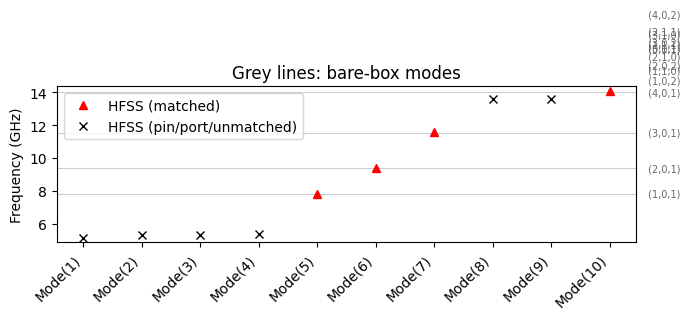

In [ ]:
box = box_modes(15)
fig, ax = plt.subplots(figsize=(7, 4))
for _, r in box.iterrows():
    ax.axhline(r["f_box (GHz)"], color="0.8", lw=0.8, zorder=0)
    ax.text(len(cavity_matched) - 0.4, r["f_box (GHz)"], f' {r["mode (m,n,l)"]}', va="center", fontsize=7, color="0.4")
ok = cavity_matched["f_box (GHz)"].notna()
ax.plot(np.flatnonzero(ok), cavity_matched.loc[ok, "Frequency_Real (GHz)"], "r^", label="HFSS (matched)")
ax.plot(np.flatnonzero(~ok), cavity_matched.loc[~ok, "Frequency_Real (GHz)"], "kx", label="HFSS (pin/port/unmatched)")
ax.set_xticks(range(len(cavity_matched)))
ax.set_xticklabels(cavity_matched["Eigenmode"], rotation=45, ha="right")
ax.set_ylabel("Frequency (GHz)")
ax.set_ylim(cavity_matched["Frequency_Real (GHz)"].min() - 0.3, cavity_matched["Frequency_Real (GHz)"].max() + 0.3)
ax.set_title("Grey lines: bare-box modes")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(BASE / "figures/cavity_modes.pdf")
plt.show()

### Field plots
Mag_E of the two lowest cavity modes (the TE101/TE110 pair when `cav_W == cav_H`) on the seam plane
(`Global:XY`, z = 0, where the chips sit) and across the cavity (`Global:YZ`). Plots appear under
*Field Overlays* in AEDT and are exported as JPGs to `figures/`.

Note: in an eigenmode design **every** overlay shows whichever mode is currently selected in
*HFSS > Fields > Edit Sources*. The JPGs are exported right after each mode is selected, so they are
correct; in the AEDT window, call `show_mode(k, n_modes)` (or use Edit Sources) to switch what you see.

In [ ]:
n_modes = len(cavity_results)
cavity_modes = cavity_matched.index[cavity_matched["f_box (GHz)"].notna()][:2]   # two lowest real cavity modes
for idx in cavity_modes:
    k = idx + 1                                   # HFSS mode numbers are 1-based
    show_mode(k, n_modes)
    for plane in ("Global:XY", "Global:YZ"):
        plot_field_cut(plane, "Mag_E", SETUP_EM_CAVITY, f"MagE_mode{k}_{plane.split(':')[1]}")
print("plotted modes:", [i + 1 for i in cavity_modes])
hfss.save_project()

PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Active Design set to EM_Cavity
plotted modes: [5, 6]
PyAEDT INFO: Project coffin_4Q Saved correctly


True

## Cavity + Transmons
Four **asymmetric transmons**, one chip per tunnel, built natively in HFSS. Pad / junction / chip dimensions
come from the previous cavity's transmon (positions from that design are not used):

| | |
|---|---|
| pad 1 (short, tip side) | 2000 × 200 µm |
| pad 2 (long) | 4000 × 200 µm |
| junction | 30 × 30 µm, with 85 µm × 30 µm leads each side (pad gap = 200 µm) |
| chip | sapphire, 16.63 mm long × 2.45 mm wide × 0.43 mm thick |
| mesh | jj 10 µm, pads 50 µm, substrate 0.5 mm |

Layout here: chip sits on the tunnel floor, dipole along y. The short pad is at the chip tip inside the cavity
(65 µm from the tip, as in the old chip), the junction is near the cavity wall (`protrude`), and the long pad runs
back into the tunnel under the drive pin. The substrate is left **inside** the vacuum (not subtracted), as in the
old code, so the chip faces don't become PerfE. Junction inductances are design variables `Lj1..Lj4`; each
junction also gets a non-model line `jj_line_i` for pyEPR.

In [ ]:
UM = 1e-3   # um -> mm

CHIP = {
    "material":   "sapphire",
    "L":          16.63,          # mm, chip length (along the tunnel, y)
    "W":          2.45,           # mm, chip width (x)
    "T":          0.43,           # mm, chip thickness (sits on the tunnel floor)
    "protrude":   1.0,            # mm, chip tip past the cavity -y wall (puts the junction near the wall)
    "pad_margin": 65 * UM,        # chip tip to short pad (old chip: half-length - 5.5 * 1500 um)
    "pad1_L":     2000 * UM,      # short pad (tip / cavity side)
    "pad2_L":     4000 * UM,      # long pad (tunnel / drive side)
    "pad_W":      200 * UM,
    "jj_L":       30 * UM,        # junction length (along the dipole, y)
    "jj_W":       30 * UM,        # junction width (x) = lead width
    "lead_L":     85 * UM,
}
CHIP["pad_gap"] = CHIP["jj_L"] + 2 * CHIP["lead_L"]       # 200 um

LJ_NH = [11.0, 12.0, 13.0, 14.0]   # PLACEHOLDER junction inductances (nH), staggered so qubit modes separate
CJ_FF = None                        # junction capacitance (fF) or None
JJ_PORT_Z = 1e6                     # ohm, driven-modal junction port (SNAIL value; essentially open)
CJ_BBQ_FF = CJ_FF if CJ_FF is not None else 4.0   # fF, junction capacitance added in BBQ (SNAIL: 4 fF)

MESH = {"substrate": "0.5mm", "pads": "50um", "jj": "10um"}


def chip_layout(i):
    # Geometry (mm, global coords) of chip i (1..4). Rectangles are (origin, [dx, dy]) in the plane z = z_top.
    c = CHIP
    x = QUBIT_X[i - 1]
    z_floor = -P["chip_T"]                       # tunnel floor (Inventor pocket depth)
    z_top = z_floor + c["T"]                     # chip top surface = pad plane
    y_tip = -P["cav_W"] / 2 + c["protrude"]
    y_back = y_tip - c["L"]
    y_p1_hi = y_tip - c["pad_margin"]            # short pad, tip side
    y_p1_lo = y_p1_hi - c["pad1_L"]
    y_jj_hi = y_p1_lo - c["lead_L"]
    y_jj_lo = y_jj_hi - c["jj_L"]
    y_p2_hi = y_p1_lo - c["pad_gap"]             # long pad
    y_p2_lo = y_p2_hi - c["pad2_L"]
    xp, xj = x - c["pad_W"] / 2, x - c["jj_W"] / 2
    return dict(
        x=x, z_floor=z_floor, z_top=z_top, y_tip=y_tip, y_back=y_back, y_jj=(y_jj_lo + y_jj_hi) / 2,
        pad1=([xp, y_p1_lo, z_top], [c["pad_W"], c["pad1_L"]]),
        lead1=([xj, y_jj_hi, z_top], [c["jj_W"], c["lead_L"]]),
        jj=([xj, y_jj_lo, z_top], [c["jj_W"], c["jj_L"]]),
        lead2=([xj, y_p2_hi, z_top], [c["jj_W"], c["lead_L"]]),
        pad2=([xp, y_p2_lo, z_top], [c["pad_W"], c["pad2_L"]]),
        line=([x, y_jj_lo, z_top], [x, y_jj_hi, z_top]),
    )


# sanity checks before touching HFSS
assert CHIP["W"] <= P["tunnel_W"], "chip wider than the tunnel"
assert CHIP["T"] <= P["chip_T"] + 1e-9, "chip thicker than the tunnel pocket"
if CHIP["T"] < P["chip_T"]:
    print(f"[note] chip ({CHIP['T']} mm) is thinner than the tunnel pocket ({P['chip_T']} mm): "
          f"{(P['chip_T'] - CHIP['T']) * 1e3:.0f} um gap above the chip")
for i in range(1, 5):
    L = chip_layout(i)
    assert L["y_tip"] < P["cav_W"] / 2, f"chip {i} crosses the whole cavity"
    assert L["y_back"] > -(P["cav_W"] / 2 + P["tunnel_L"]), f"chip {i} longer than the tunnel"
    assert L["pad2"][0][1] > L["y_back"], f"chip {i}: long pad runs off the chip"
lay = pd.DataFrame({f"Q{i}": {k: chip_layout(i)[k] for k in ("x", "y_tip", "y_jj", "y_back", "z_top")}
                    for i in range(1, 5)}).round(3)
lay.loc["jj to cavity wall (mm, + = inside)"] = lay.loc["y_jj"] + P["cav_W"] / 2
lay.loc["drive pin y"] = Y_DRIVE
lay

[note] chip (0.43 mm) is thinner than the tunnel pocket (0.5 mm): 70 um gap above the chip


,Q1,Q2,Q3,Q4
x,-18.750,-6.250,6.250,18.750
y_tip,-2.800,-2.800,-2.800,-2.800
y_jj,-4.965,-4.965,-4.965,-4.965
y_back,-19.430,-19.430,-19.430,-19.430
z_top,-0.070,-0.070,-0.070,-0.070
"jj to cavity wall (mm, + = inside)",0.035,0.035,0.035,0.035
drive pin y,-7.800,-7.800,-7.800,-7.800


In [ ]:
def add_transmons(junction="rlc", port_qubits=None):
    # Add the 4 chips to the active design (call after build_cavity()). Returns pyEPR junction info.
    # junction="rlc": each jj sheet is a lumped inductor Lj_i (eigenmode / pyEPR).
    # junction="port": each jj sheet is a lumped port jj_i of JJ_PORT_Z (driven modal / BBQ).
    # junction="mixed": qubits in port_qubits get lumped ports, the rest stay lumped inductors Lj_i.
    assert junction in ("rlc", "port", "mixed"), junction
    port_set = (set(range(1, 5)) if junction == "port"
                else set(port_qubits or ()) if junction == "mixed" else set())
    assert junction != "mixed" or port_set, "junction='mixed' needs port_qubits, e.g. [1]"
    for op in list(getattr(hfss.mesh, "meshoperations", [])):    # clean rerun
        try:
            op.delete()
        except Exception:
            pass

    omodule = hfss.odesign.GetModule("BoundarySetup")
    subs, pads, jjs, junctions = [], [], [], {}
    for i in range(1, 5):
        L = chip_layout(i)
        if i not in port_set:
            hfss[f"Lj{i}"] = f"{LJ_NH[i - 1]}nH"                 # design variable (pyEPR / sweeps)

        sub = hfss.modeler.create_box(origin=[L["x"] - CHIP["W"] / 2, L["y_back"], L["z_floor"]],
                                      sizes=[CHIP["W"], CHIP["L"], CHIP["T"]],
                                      name=f"substrate_{i}", material=CHIP["material"])
        sub.transparency = 0.9

        # pads + leads (united), junction sheet, pyEPR line
        p1 = hfss.modeler.create_rectangle("XY", *L["pad1"], name=f"pad_{i}a")
        l1 = hfss.modeler.create_rectangle("XY", *L["lead1"], name=f"lead_{i}a")
        p2 = hfss.modeler.create_rectangle("XY", *L["pad2"], name=f"pad_{i}b")
        l2 = hfss.modeler.create_rectangle("XY", *L["lead2"], name=f"lead_{i}b")
        hfss.modeler.unite([p1.name, l1.name])
        hfss.modeler.unite([p2.name, l2.name])
        jj = hfss.modeler.create_rectangle("XY", *L["jj"], name=f"jj_{i}")
        hfss.modeler.create_polyline(list(L["line"]), name=f"jj_line_{i}", non_model=True)

        hfss.assign_perfecte_to_sheets([p1.name, p2.name], f"pads_{i}")
        if i in port_set:
            # same call as the SNAIL notebook; the integration line is the jj current line (along y)
            hfss._create_lumped_driven(assignment=jj.name, int_line_start=L["line"][0],
                                       int_line_stop=L["line"][1], impedance=JJ_PORT_Z,
                                       port_name=f"jj{i}", renorm=False, deemb=False)
        else:
            start, end = ([f"{v}mm" for v in pt] for pt in L["line"])
            rlc = ["NAME:jj" + str(i), "Objects:=", [jj.name],
                   ["NAME:CurrentLine", "Start:=", start, "End:=", end],
                   "RLC Type:=", "Parallel", "UseResist:=", False,
                   "UseInduct:=", True, "Inductance:=", f"Lj{i}",
                   "UseCap:=", CJ_FF is not None]
            if CJ_FF is not None:
                rlc += ["Capacitance:=", f"{CJ_FF}fF"]
            omodule.AssignLumpedRLC(rlc)

        subs.append(sub.name); pads += [p1.name, p2.name]; jjs.append(jj.name)
        junctions[f"j{i}"] = {"Lj_variable": f"Lj{i}", "rect": jj.name, "line": f"jj_line_{i}",
                              "length": f"{CHIP['jj_L']}mm"}

    hfss.mesh.assign_length_mesh(subs, inside_selection=False, maximum_length=MESH["substrate"],
                                 maximum_elements=None, name="tmon_substrate")
    hfss.mesh.assign_length_mesh(pads, inside_selection=False, maximum_length=MESH["pads"],
                                 maximum_elements=None, name="tmon_pads")
    hfss.mesh.assign_length_mesh(jjs, inside_selection=False, maximum_length=MESH["jj"],
                                 maximum_elements=None, name="tmon_jj")
    hfss.modeler.fit_all()
    kinds = {i: ("port" if i in port_set else "Lj") for i in range(1, 5)}
    print(f"[chips] {len(subs)} asymmetric transmons; junctions: "
          + ", ".join(f"Q{i}={k}" for i, k in kinds.items())
          + f" (ports {JJ_PORT_Z:g} ohm, Lj = {LJ_NH} nH)")
    return junctions

In [ ]:
use_design("EM_Cavity_with_Transmons")
ports = build_cavity()
JUNCTIONS = add_transmons()

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 8892!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q.stp imported
PyAEDT INFO: Materials 

Setup: `MinimumFrequency = 3 GHz` so the qubits (≈4–6 GHz) are included. That also brings back the four
low-Q drive-pin modes near 4.3 GHz, so convergence may again be limited by them; check the convergence
table in AEDT. `NumModes = 12` = 4 qubits + 4 pin modes + the first cavity modes.

In [ ]:
SETUP_EM_TRANSMONS = "EM_Cavity_with_Transmons"
eigen_setup(SETUP_EM_TRANSMONS,
            MinimumFrequency="3GHz",
            NumModes=12,
            MaxDeltaFreq=0.1,
            ConvergeOnRealFreq=True,
            MaximumPasses=20,
            MinimumPasses=2,
            MinimumConvergedPasses=2,
            BasisOrder=-1)
hfss.analyze(setup=SETUP_EM_TRANSMONS, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.47895240783691406
PyAEDT INFO: Project coffin_4Q Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup EM_Cavity_with_Transmons
PyAEDT INFO: Design setup EM_Cavity_with_Transmons solved correctly in 0.0h 56.0m 39.0s
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Project coffin_4Q Saved correctly


True

### Results
Modes are labeled with the nearest bare-box mode where it fits; low-Q modes are the drive pins.
The rest are **qubit-like** (high Q, no box match). EPR below gives the definitive junction participation.

In [ ]:
tm_results = eigenmode_results("cavity_transmons_eigenmode_results.csv")
tm_matched = match_box_modes(tm_results)
tm_matched["box mode"] = tm_matched["box mode"].replace("unmatched", "qubit-like")
tm_matched

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.49074840545654297
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 1sec
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.04363894462585449
Time to initialize solution data:0.04363894462585449
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.032656192779541016
Time to initialize solution data:0.0400092601776123

,Eigenmode,Frequency_Real (GHz),Frequency_Imag (GHz),Q,box mode,f_box (GHz),f - f_box (MHz)
0,Mode(1),3.662954,0.000005,403916.497849,qubit-like,NaN,NaN
1,Mode(2),3.794534,0.000005,381691.934308,qubit-like,NaN,NaN
2,Mode(3),3.956046,0.000006,353117.137881,qubit-like,NaN,NaN
3,Mode(4),4.122196,0.000006,325643.109241,qubit-like,NaN,NaN
4,Mode(5),5.385333,0.457748,5.903630,pin/port mode (low Q),NaN,NaN
5,Mode(6),5.385518,0.457680,5.904704,pin/port mode (low Q),NaN,NaN
6,Mode(7),5.385904,0.457923,5.902019,pin/port mode (low Q),NaN,NaN
7,Mode(8),5.386235,0.457529,5.907422,pin/port mode (low Q),NaN,NaN
8,Mode(9),7.769362,0.000055,71257.772193,"(1,0,1)",7.805249,-35.887046
9,Mode(10),9.342628,0.000055,85267.517295,"(2,0,1)",9.374677,-32.048435


In [ ]:
# Mag_E on the seam plane for every qubit-like mode
n_modes = len(tm_results)
qubit_modes = [i + 1 for i in tm_matched.index[tm_matched["box mode"] == "qubit-like"]]
for k in qubit_modes:
    show_mode(k, n_modes)
    plot_field_cut("Global:XY", "Mag_E", SETUP_EM_TRANSMONS, f"TM_MagE_mode{k}_XY")
print("qubit-like modes:", qubit_modes)
hfss.save_project()

PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
qubit-like modes: [1, 2, 3, 4, 12]
PyAEDT INFO: Project coffin_4Q Saved correctly


True

### EPR (pyEPR 0.8)
Energy-participation analysis of all four junctions: qubit frequencies, anharmonicities, cross-Kerrs and
dispersive shifts. Set `RUN_EPR = True` once the eigenmode solve above has converged.
pyEPR 0.8 needs the numpy 2 / pandas 2 compatibility patches, applied here before it is imported.

In [ ]:
RUN_EPR = True

if RUN_EPR:
    # --- pyEPR 0.8 compat (removed numpy aliases, pandas .append / .iteritems) ---
    for alias, target in {"float": float, "int": int, "complex": complex, "bool": bool, "object": object,
                          "str": str, "float_": np.float64, "complex_": np.complex128,
                          "NaN": np.nan, "Inf": np.inf, "infty": np.inf, "product": np.prod,
                          "cumproduct": np.cumprod, "alltrue": np.all, "sometrue": np.any}.items():
        if alias not in np.__dict__:
            setattr(np, alias, target)
    if not hasattr(pd.DataFrame, "append"):
        def _df_append(self, other, ignore_index=False, verify_integrity=False, sort=False):
            if isinstance(other, pd.Series):
                other = other.to_frame().T
            elif isinstance(other, dict):
                other = pd.DataFrame([other])
            elif isinstance(other, (list, tuple)):
                return pd.concat([self, *other], ignore_index=ignore_index, sort=sort)
            return pd.concat([self, other], ignore_index=ignore_index, sort=sort)
        pd.DataFrame.append = _df_append
    if not hasattr(pd.Series, "append"):
        pd.Series.append = lambda self, o, ignore_index=False, verify_integrity=False: pd.concat(
            [self, *(o if isinstance(o, (list, tuple)) else [o])], ignore_index=ignore_index)
    for cls in (pd.DataFrame, pd.Series):
        if not hasattr(cls, "iteritems"):
            cls.iteritems = cls.items
    # pandas 2: drop(labels, axis) no longer takes axis positionally (pyEPR ansys.py: .drop('Unnamed: 3', 1))
    if not getattr(pd.DataFrame.drop, "_epr_compat", False):
        _df_drop = pd.DataFrame.drop

        def _drop_compat(self, labels=None, *args, **kwargs):
            if args:
                kwargs.setdefault("axis", args[0])
            return _df_drop(self, labels, **kwargs)
        _drop_compat._epr_compat = True
        pd.DataFrame.drop = _drop_compat

    import pyEPR as epr
    # pint >= 0.2x parses "0" as Quantity(0), which pyEPR 0.8 uses as a tuple index for variations.
    # Wrap its registry: calling it with a variation string gives an int; .Quantity etc. pass through.
    import pyEPR.core_distributed_analysis as _epr_cda

    class _VariationUreg:
        def __init__(self, ureg):
            self._ureg = ureg

        def __call__(self, s):
            return int(s) if str(s).strip().isdigit() else self._ureg(s)

        def __getattr__(self, name):
            return getattr(self._ureg, name)

    if not isinstance(_epr_cda.ureg, _VariationUreg):
        _epr_cda.ureg = _VariationUreg(epr.ansys.ureg)
    # pyEPR styles its 'Freq. vs. pass' HFSS report (line width, axis units) with ChangeProperty, which
    # AEDT 2023.2 rejects. Cosmetic only (the report data is not used), so log and carry on.
    if not getattr(_epr_cda.set_property, "_epr_compat", False):
        _set_property = _epr_cda.set_property

        def _set_property_compat(*args, **kwargs):
            try:
                return _set_property(*args, **kwargs)
            except Exception as e:
                print(f"[epr] skipped HFSS report styling {args[1:4]}: {e}")
        _set_property_compat._epr_compat = True
        _epr_cda.set_property = _set_property_compat
    # QuTiP 5: bra * ket is a complex number, not a 1x1 Qobj, so pyEPR's make_dispersive fails on .norm().
    # Recompile it in its own module with abs(<a|b>) (same value, works in QuTiP 4 and 5).
    import inspect
    import pyEPR.calcs.back_box_numeric as _epr_bbn
    if not getattr(_epr_bbn.make_dispersive, "_epr_compat", False):
        _src = inspect.getsource(_epr_bbn.make_dispersive)
        for _old, _new in [("(s.dag() * s2[1]).norm()", "abs(s.overlap(s2[1]))"),
                           ("(vector1.dag() * evec).norm()", "abs(vector1.overlap(evec))")]:
            assert _old in _src, f"pyEPR make_dispersive changed; patch not applied ({_old})"
            _src = _src.replace(_old, _new)
        exec(compile(_src, _epr_bbn.__file__, "exec"), _epr_bbn.__dict__)
        _epr_bbn.make_dispersive._epr_compat = True
    # pyEPR's _config_user.py saves to D:\data-pyEPR (no D: drive here); keep results with the project
    epr.config.root_dir = str(BASE / "data" / "pyEPR")

    hfss.save_project()
    pinfo = epr.ProjectInfo(project_path=str(AEDT.parent), project_name=NAME,
                            design_name="EM_Cavity_with_Transmons", setup_name=SETUP_EM_TRANSMONS)
    for name, j in JUNCTIONS.items():
        pinfo.junctions[name] = {**j, "length": epr.parse_units(j["length"])}
    pinfo.validate_junction_info()
    pinfo.dissipative["dielectrics_bulk"] = [f"substrate_{i}" for i in range(1, 5)]

    # Modes for EPR + numerical diagonalization: one qubit + the readout mode (2x2 chi matrix).
    # Qubit = lowest qubit-like mode; readout = lowest cavity (box-matched, high-Q) mode. The low-Q drive-pin
    # modes and the other cavity modes are left out. Indices are 0-based HFSS mode numbers (Mode(k) -> k - 1).
    EPR_FOCK_TRUNC = 7
    if "tm_matched" not in globals():
        tm_matched = match_box_modes(pd.read_csv(BASE / "data/eigenmode/cavity_transmons_eigenmode_results.csv"))
        tm_matched["box mode"] = tm_matched["box mode"].replace("unmatched", "qubit-like")
    labels = tm_matched["box mode"]
    qubit_mode = int(tm_matched.index[labels == "qubit-like"][0])
    readout_mode = int(tm_matched.index[~labels.isin(["qubit-like", "pin/port mode (low Q)"])][0])
    EPR_MODES = sorted([qubit_mode, readout_mode])
    f_col = tm_matched["Frequency_Real (GHz)"]
    print(f"[epr] qubit = Mode({qubit_mode + 1}) at {f_col[qubit_mode]:.4f} GHz, "
          f"readout = Mode({readout_mode + 1}) {labels[readout_mode]} at {f_col[readout_mode]:.4f} GHz")

    # Check the readout choice: it must sit near READOUT_F_GHZ (default: lowest analytic box mode, the
    # (1,0,1) at ~7.8 GHz for 50 x 15 x 20.8 mm). Otherwise a different mode was picked; stop before EPR.
    READOUT_F_GHZ = None          # GHz, or None for the lowest bare-box mode
    READOUT_TOL = 0.03            # relative
    box0 = box_modes(1).iloc[0]
    f_target = READOUT_F_GHZ if READOUT_F_GHZ is not None else box0["f_box (GHz)"]
    target_src = "READOUT_F_GHZ" if READOUT_F_GHZ is not None else f"{box0['mode (m,n,l)']} bare box"
    f_ro = f_col[readout_mode]
    if abs(f_ro - f_target) / f_target > READOUT_TOL:
        near = tm_matched.loc[(f_col - f_target).abs().idxmin()]
        raise RuntimeError(
            f"readout pick Mode({readout_mode + 1}) at {f_ro:.4f} GHz is not within {READOUT_TOL:.0%} of the expected "
            f"{f_target:.4f} GHz ({target_src}). Closest HFSS mode: {near['Eigenmode']} at "
            f"{near['Frequency_Real (GHz)']:.4f} GHz, Q = {near['Q']:.3g}, labelled '{near['box mode']}'. "
            f"Check tm_matched, or set READOUT_F_GHZ.")
    print(f"[epr] readout check ok: {f_ro:.4f} GHz vs expected {f_target:.4f} GHz "
          f"({(f_ro - f_target) / f_target:+.2%})")

    eprd = epr.DistributedAnalysis(pinfo)
    eprd.do_EPR_analysis(modes=EPR_MODES)
    epra = epr.QuantumAnalysis(eprd.data_filename)
    epra.analyze_all_variations(cos_trunc=8, fock_trunc=EPR_FOCK_TRUNC)
    epra.report_results(numeric=True)

PyAEDT INFO: Project coffin_4Q Saved correctly


INFO 01:42PM [connect]: Connecting to Ansys Desktop API...
INFO 01:42PM [load_ansys_project]: 	File path to HFSS project found.
INFO 01:42PM [load_ansys_project]: 	Opened Ansys App
INFO 01:42PM [load_ansys_project]: 	Opened Ansys Desktop v2023.2.0
INFO 01:42PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/epm114/Documents/GitHub/Cavity work/coffin_4Q/hfss_files/
	Project:   coffin_4Q
INFO 01:42PM [connect]: 	Opened active design
	Design:    EM_Cavity_with_Transmons [Solution type: Eigenmode]
INFO 01:42PM [get_setup]: 	Opened setup `EM_Cavity_with_Transmons`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 01:42PM [connect]: 	Connection to Ansys established successfully. 😀 



[epr] qubit = Mode(1) at 3.3253 GHz, readout = Mode(6) (1,0,1) at 7.8079 GHz
[epr] readout check ok: 7.8079 GHz vs expected 7.8052 GHz (+0.03%)
Design "EM_Cavity_with_Transmons" info:
	# eigenmodes    12
	# variations    1

Variation 0  [1/1]

  Mode 0 at 3.33 GHz   [1/12]
    Calculating ℰ_magnetic,ℰ_electric
       (ℰ_E-ℰ_H)/ℰ_E       ℰ_E       ℰ_H
               91.1%  9.787e-24 8.694e-25

    Calculating junction energy participation ration (EPR)
	method=`line_voltage`. First estimates:
	junction        EPR p_0j   sign s_0j    (p_capacitive)
		Energy fraction (Lj over Lj&Cj)= 99.05%
	j1              0.910266  (+)        0.00874222
		Energy fraction (Lj over Lj&Cj)= 98.96%
	j2              1.12673e-11  (+)        1.18049e-13
		Energy fraction (Lj over Lj&Cj)= 98.88%
	j3              1.45205e-13  (+)        1.64811e-15
		Energy fraction (Lj over Lj&Cj)= 98.79%
	j4              2.00631e-15  (+)        2.45238e-17
		(U_tot_cap-U_tot_ind)/mean=0.48%
Calculating Qdielectric_substrate_1 f

WARNING 01:42PM [__init__]: <p>Error: <class 'IndexError'></p>


[epr] skipped HFSS report styling ('Attributes', ['Freq. vs. pass:re(Mode(1)):Curve1', 'Freq. vs. pass:re(Mode(2)):Curve1', 'Freq. vs. pass:re(Mode(3)):Curve1', 'Freq. vs. pass:re(Mode(4)):Curve1', 'Freq. vs. pass:re(Mode(5)):Curve1', 'Freq. vs. pass:re(Mode(6)):Curve1', 'Freq. vs. pass:re(Mode(7)):Curve1', 'Freq. vs. pass:re(Mode(8)):Curve1', 'Freq. vs. pass:re(Mode(9)):Curve1', 'Freq. vs. pass:re(Mode(10)):Curve1', 'Freq. vs. pass:re(Mode(11)):Curve1', 'Freq. vs. pass:re(Mode(12)):Curve1'], 'Line Width'): (-2147352567, 'Exception occurred.', (0, None, None, None, 0, -2147024382), None)

ANALYSIS DONE. Data saved to:

C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\data\pyEPR\coffin_4Q\EM_Cavity_with_Transmons\2026-11-02 13-42-12.npz


	 Differences in variations:



 . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . 
Variation 0

Starting the diagonalization
Finished the diagonalization
Pm_norm=
modes
0     1.010120
5    17.426476
dtype: float64



#### Mode frequencies (MHz)

###### Numerical diagonalization

variation,0
eigenmode,
0,3248.05
1,7807.93


#### Kerr Non-linear coefficient table (MHz)

###### Numerical diagonalization

0                               1
variation                                                                  
0         0  8.10e+01+0.00e+            00j  1.11e-04+0.00e+            00j
          1  1.11e-04+0.00e+            00j  1.81e-09+0.00e+            00j

# Driven Modal: single port (one qubit)
Simpler version of the driven-modal + BBQ flow, run before the 4-port one. Same cavity, chips, boundaries, setup
and sweeps as `DM`, except:

* **one** junction (`Q_DRIVE`, the highest-frequency qubit = smallest `Lj`) is a lumped port `jjQ`,
* the other **three** junctions stay **lumped inductors** `Lj1..Lj4` (design variables), exactly as in `EM_Cavity_with_Transmons`.

HFSS then returns a single admittance `Y(jjQ,jjQ)`: what that junction sees with the other qubits already in
place as linear inductors. That is the quantity the 4-port section builds analytically (`reduced_admittance`),
so the two should agree up to C_J on the other junctions (here none in HFSS, 4 fF in the 4-port reduction) and
mesh differences. The catch: changing `Lj2..Lj4` now needs a new HFSS solve.

Only Q_DRIVE gets `C_J = CJ_BBQ_FF` (added in BBQ); the inductor junctions have no C_J, as in the eigenmode design.

In [ ]:
# highest-frequency qubit: the chips are identical, so it is the one with the smallest Lj
Q_DRIVE = int(np.argmin(LJ_NH)) + 1
PORT_DM1 = f"jj{Q_DRIVE}"
DESIGN_DM1 = f"DM_1port_Q{Q_DRIVE}"
SETUP_DM1 = "DM_1port"
DM1_FREQ = "7GHz"                                                 # same as DM
DM1_SWEEP = dict(start=3.0, stop=10.0, chunk=0.1, points=10_000)   # same as DM: GHz, GHz, GHz, points/chunk
for d in ("data/driven_modal", "data/bbq", "figures"):
    (BASE / d).mkdir(parents=True, exist_ok=True)

if "tm_results" in globals():   # cross-check against the eigenmode run, if it is in memory
    tm_q = tm_results[tm_results["Q"] > 1e3].nsmallest(4, "Frequency_Real (GHz)")
    print("eigenmode qubit-like modes (GHz):", tm_q["Frequency_Real (GHz)"].round(4).tolist())
print(f"driven junction: Q{Q_DRIVE} (Lj = {LJ_NH[Q_DRIVE - 1]} nH) -> port {PORT_DM1}; "
      f"others are inductors {[f'Lj{k}' for k in range(1, 5) if k != Q_DRIVE]}")

eigenmode qubit-like modes (GHz): [3.3253, 7.8079, 9.3886, 10.4007]
driven junction: Q1 (Lj = 11.0 nH) -> port jj1; others are inductors ['Lj2', 'Lj3', 'Lj4']


In [ ]:
use_design(DESIGN_DM1, "Modal")
ports = build_cavity()
JUNCTIONS_DM1 = add_transmons(junction="mixed", port_qubits=[Q_DRIVE])

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 8892!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to DM_1port_Q1
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q.stp imported
PyAEDT INFO: Materials class has bee

### Setup and sweeps
Identical to the 4-port `DM` setup (adaptive mesh at 7 GHz, fast sweeps 3–10 GHz in 100 MHz chunks × 10 000
points = 10 kHz step). With one port there is a single Y entry per point, so the data are ~16× smaller.
Note: `MaxDeltaE` is kept for parity with `DM`, but it is not a driven-setup property and is ignored, so HFSS
uses its default ΔS = 0.02 (true for `DM` too).

In [ ]:
if SETUP_DM1 in hfss.get_setups():
    hfss.delete_setup(SETUP_DM1)                                 # also removes its sweeps
hfss.create_setup(name=SETUP_DM1,
                  SolveType="Single",
                  Frequency=DM1_FREQ,
                  MaxDeltaE=0.01,
                  MaximumPasses=10,
                  MinimumPasses=3,
                  MinimumConvergedPasses=3,
                  PercentRefinement=30,
                  BasisOrder=-1,
                  DoLambdaRefine=True,
                  DoMaterialLambda=True,
                  SetLambdaTarget=False,
                  Target=0.3333,
                  UseMaxTetIncrease=False,
                  DrivenSolverType="Direct Solver",
                  EnhancedLowFreqAccuracy=False,
                  SaveRadFieldsOnly=False,
                  SaveAnyFields=True)

n_chunks = int(round((DM1_SWEEP["stop"] - DM1_SWEEP["start"]) / DM1_SWEEP["chunk"]))
edges = np.linspace(DM1_SWEEP["start"], DM1_SWEEP["stop"], n_chunks + 1)
for k, (f0, f1) in enumerate(zip(edges, edges[1:])):
    hfss.create_linear_count_sweep(setup=SETUP_DM1, units="GHz",
                                   start_frequency=round(float(f0), 6), stop_frequency=round(float(f1), 6),
                                   num_of_freq_points=DM1_SWEEP["points"], name=f"Sweep_{k:03d}",
                                   save_fields=False, sweep_type="Fast")
print(f"[dm1] {n_chunks} fast sweeps, {edges[0]:g}-{edges[-1]:g} GHz, port {PORT_DM1}")

hfss.analyze(setup=SETUP_DM1, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Key MaxDeltaE matched internal key 'MaxDeltaS' with confidence of 88.
PyAEDT INFO: Key DrivenSolverType matched internal key 'SolveType' with confidence of 72.
PyAEDT INFO: Key EnhancedLowFreqAccuracy matched internal key 'PortAccuracy' with confidence of 56.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is 

True

### Admittance seen by the junction
Reads `Y(jjQ,jjQ)` (real and imaginary) from every sweep, drops the duplicated chunk-edge points and saves
`data/driven_modal/Y_Q<n>_single_port.npz` (`f` in Hz, `Y` in S).

In [ ]:
def single_port_y(port=PORT_DM1, setup=SETUP_DM1, sweep_cfg=DM1_SWEEP):
    # Y(port,port) from every sweep of `setup` -> (f [Hz], Y [S], complex).
    expr = f"Y({port},{port})"
    f_all, y_all = [], []
    for sweep in sorted(hfss.get_sweeps(setup)):
        data = hfss.post.get_solution_data(expressions=expr, setup_sweep_name=f"{setup} : {sweep}")
        if not data:
            raise RuntimeError(f"no solution data for {setup} : {sweep} (not solved?)")
        x, re = data.get_expression_data(expr, formula="real", convert_to_SI=True)
        _, im = data.get_expression_data(expr, formula="imag", convert_to_SI=True)
        f_all.append(np.asarray(x, dtype=float))
        y_all.append(np.asarray(re) + 1j * np.asarray(im))
    f, y = np.concatenate(f_all), np.concatenate(y_all)
    f, keep = np.unique(f, return_index=True)          # sorted, without the shared chunk edges
    lo, hi = sweep_cfg["start"] * giga, sweep_cfg["stop"] * giga
    assert lo * 0.999 <= f[0] and f[-1] <= hi * 1.001, f"frequency axis {f[0]}..{f[-1]} is not in Hz"
    return f, y[keep]


Y1_NPZ = BASE / "data/driven_modal" / f"Y_Q{Q_DRIVE}_single_port.npz"
f_dm1, Y_dm1 = single_port_y()
np.savez(Y1_NPZ, f=f_dm1, Y=Y_dm1, port=PORT_DM1, Lj_nH=LJ_NH)
print(f"[dm1] {len(f_dm1)} points, {f_dm1[0] / giga:g}-{f_dm1[-1] / giga:g} GHz -> {Y1_NPZ.name}")

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: aedt file load time 0.6233699321746826
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.0446927547454834
Time to initialize solution data:0.07633733749389648
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.040883779525756836
Time to initialize solution data:0.057942867279052734
P

INFO 06:05PM [__del__]: Disconnected from Ansys HFSS
INFO 06:05PM [__del__]: Disconnected from Ansys HFSS
INFO 06:05PM [__del__]: Disconnected from Ansys HFSS


Warning! 3 COM references still alive
HFSS will likely refuse to shut down
Warning! 3 COM references still alive
HFSS will likely refuse to shut down


INFO 06:05PM [__del__]: Disconnected from Ansys HFSS


Warning! 3 COM references still alive
HFSS will likely refuse to shut down
Warning! 3 COM references still alive
HFSS will likely refuse to shut down
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.0426630973815918
Time to initialize solution data:0.06256794929504395
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.0416569709777832
Time to initialize solution data:0.058686256408691406
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.03854250907897949
Time to initialize solution data:0.05556440353393555
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.040838003158569336
Time to initialize solution d

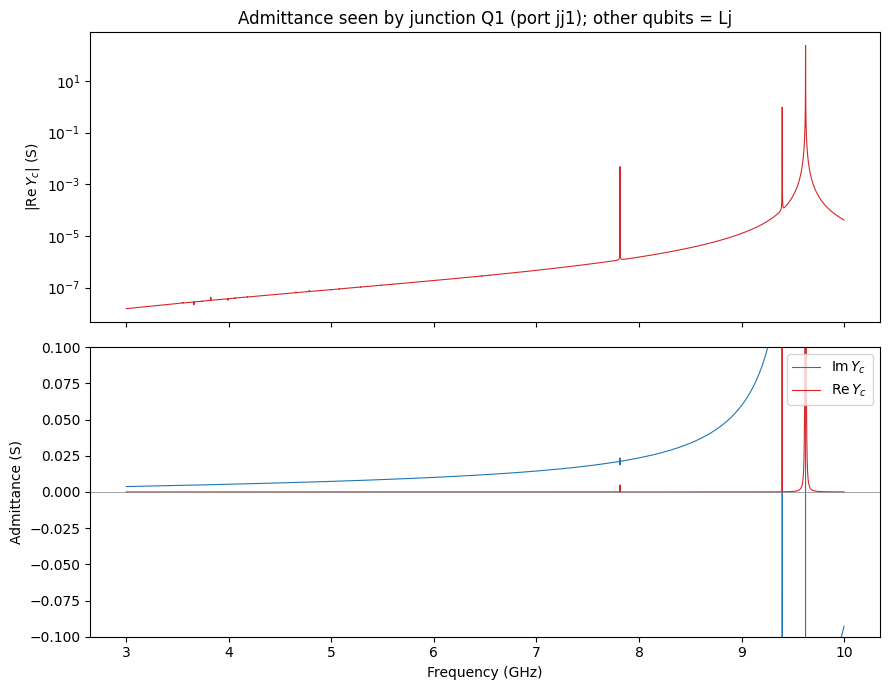

In [ ]:
# Admittance graph: Re(Y) alone, then Re(Y) and Im(Y) together  (reloads from disk; no HFSS needed)
Y1_NPZ = BASE / "data/driven_modal" / f"Y_Q{Q_DRIVE}_single_port.npz"   # so this cell runs without HFSS
d1 = np.load(Y1_NPZ)
f_dm1, Y_dm1 = d1["f"], d1["Y"]
fg = f_dm1 / giga

fig, (ax_re, ax_both) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax_re.semilogy(fg, np.abs(Y_dm1.real), color="tab:red", lw=0.8)
ax_re.set_ylabel(r"$|\mathrm{Re}\,Y_c|$ (S)")
ax_re.set_title(f"Admittance seen by junction Q{Q_DRIVE} (port {PORT_DM1}); other qubits = Lj")

ax_both.plot(fg, Y_dm1.imag, color="tab:blue", lw=0.8, label=r"$\mathrm{Im}\,Y_c$")
ax_both.plot(fg, Y_dm1.real, color="tab:red", lw=0.8, label=r"$\mathrm{Re}\,Y_c$")
ax_both.axhline(0, color="0.5", lw=0.5)
ax_both.set_ylim(-0.1, 0.1)
ax_both.set_xlabel("Frequency (GHz)")
ax_both.set_ylabel("Admittance (S)")
ax_both.legend(loc="upper right")
fig.tight_layout()
fig.savefig(BASE / "figures" / f"admittance_Q{Q_DRIVE}_single_port.pdf")
plt.show()

### Black-box quantization of Q_DRIVE (pybbq)
Full single-junction routine: add the junction's linear admittance (`L_J = LJ_NH[Q_DRIVE - 1]` (placeholder),
`C_J = CJ_BBQ_FF`) → modes at the upward zero crossings of Im(Y_c + Y_J) → per-mode L, C, R, Z, Φ_zpf, Q →
couplings g, participation ratios → χ matrix (anharmonicity, dispersive shifts to the other modes).
The qubit is the mode with the largest Φ_zpf at this junction. Runs from the saved `.npz`.

The other three qubits are real modes of this circuit, but seen from junction Q_DRIVE they have tiny Φ_zpf and
narrow zero crossings, so pybbq may not resolve them; cross-Kerr between qubits needs EPR or a multi-junction model.

In [ ]:
from pybbq import BBQAnalysis

L_J1 = LJ_NH[Q_DRIVE - 1] * 1e-9
C_J1 = CJ_BBQ_FF * 1e-15
bbq1 = BBQAnalysis(Y_dm1, f_dm1, L_J1, C_J1)
bbq1_modes = bbq1.calculate_LCRZPhi()                       # per-mode L, C, R, Z, Phi_zpf, Q
bbq1_info = bbq1.save_BBOX_info(filename=BASE / "data/bbq" / f"bbq_results_Q{Q_DRIVE}_single_port.csv")
print(f"L_J = {L_J1 * 1e9:g} nH, C_J = {C_J1 * 1e15:g} fF, qubit = mode {bbq1.qindex} "
      f"at {bbq1.f_p[bbq1.qindex] / giga:.4f} GHz")
bbq1_info

L_J = 11 nH, C_J = 4 fF, qubit = mode 0 at 3.3399 GHz


,Mode frequencies (GHz),Mode couplings (MHz),Mode inductances (nH),Mode capacitances (nF),Mode resistances (Ohms),Mode impedances (Ohm),Dimensionless mode phase fluctuation,Mode Q's
0,3.339864,0.000000,10.011165,0.000227,4.742425e+07,210.084140,0.319804,225739.294997
1,9.396650,8.005341,0.000006,46.150728,3.630119e+01,0.000367,0.000423,98912.773458


Mode Frequencies: [3.33986399 9.39664966] GHz


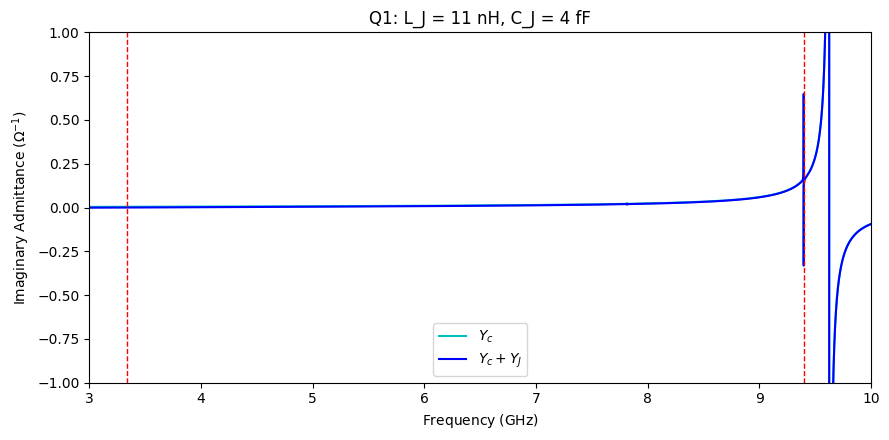

In [ ]:
# Im(Y_c) and Im(Y_c + Y_J); dashed red = modes found (zero crossings)
fig, ax = plt.subplots(figsize=(9, 4.5))
bbq1.plot_admittances(fig=fig, ax=ax, ylim=[-1, 1])
ax.set_title(f"Q{Q_DRIVE}: L_J = {L_J1 * 1e9:g} nH, C_J = {C_J1 * 1e15:g} fF")
fig.tight_layout()
fig.savefig(BASE / "figures" / f"bbq_admittance_Q{Q_DRIVE}_single_port.pdf")
plt.show()

Coupling strengths: [0.        8.0053411] MHz


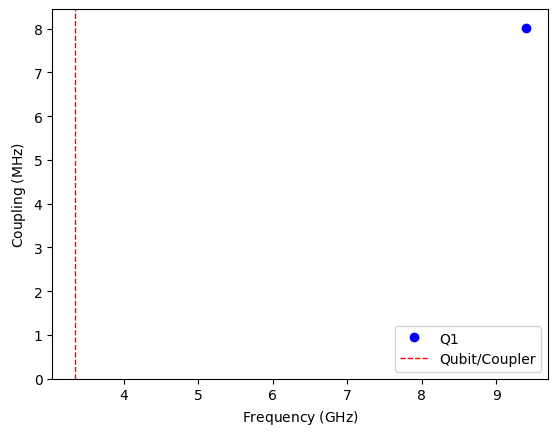

,f (GHz),g (MHz),participation (Phi/Phi_q)^2,Phi_zpf
0,3.339864,0.000000,1.000000,0.319804
1,9.396650,8.005341,0.000002,0.000423


In [ ]:
# coupling g of the qubit to every other mode, and participation ratios at this junction
fig, ax = plt.subplots()
bbq1.plot_gs_vs_freq(fig=fig, ax=ax, label=f"Q{Q_DRIVE}")
fig.savefig(BASE / "figures" / f"gs_Q{Q_DRIVE}_single_port.pdf")
plt.show()

pd.DataFrame({"f (GHz)": bbq1.f_p / giga,
              "g (MHz)": bbq1.get_gs(print_results=False) / 1e6,
              "participation (Phi/Phi_q)^2": bbq1.get_participation_ratios(),
              "Phi_zpf": bbq1.Phi_p}).round(6)

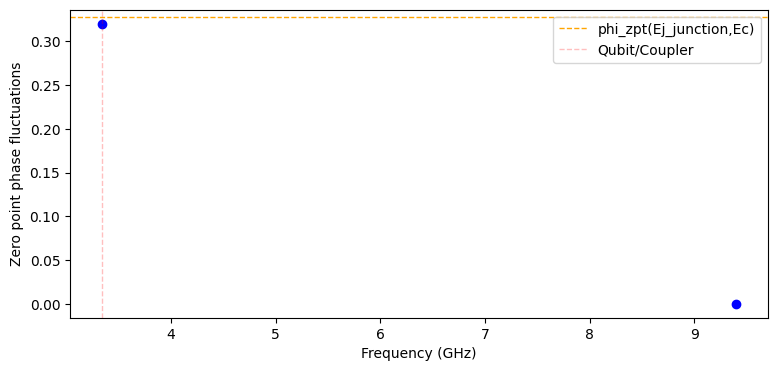

In [ ]:
# zero-point phase fluctuations per mode vs. the bare-transmon value for this L_J and E_C
fig, ax = plt.subplots(figsize=(9, 4))
bbq1.plot_phizpts(fig=fig, ax=ax)
fig.savefig(BASE / "figures" / f"phizpt_Q{Q_DRIVE}_single_port.pdf")
plt.show()

anharmonicity =  -0.07771925174562566 GHz


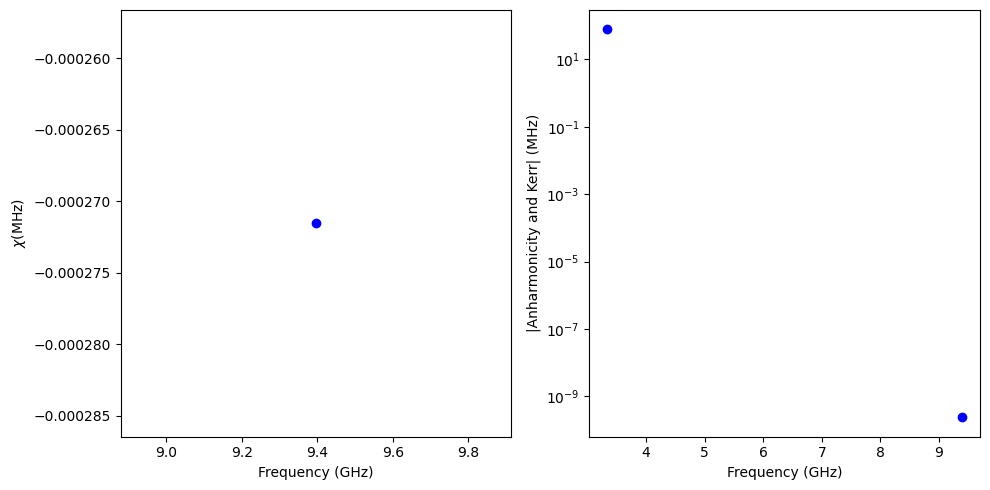

,f (GHz),Q,g to qubit (MHz),chi to qubit (MHz),self-Kerr / anharm. (MHz)
qubit,3.3399,225739.2950,0.0000,-77.7193,-77.7193
mode 1,9.3966,98912.7735,8.0053,-0.0003,-0.0000


In [ ]:
# chi matrix (GHz): diagonal = anharmonicity / self-Kerr, row q = dispersive shifts of the other modes
chi1 = bbq1.Hparams_with_transmon_circuit()
plt.savefig(BASE / "figures" / f"chi_Q{Q_DRIVE}_single_port.pdf")
plt.show()

q = bbq1.qindex
summary1 = pd.DataFrame({
    "f (GHz)": bbq1.f_p / giga,
    "Q": bbq1.Q_p,
    "g to qubit (MHz)": bbq1.get_gs(print_results=False) / 1e6,
    "chi to qubit (MHz)": chi1[q] * 1e3,
    "self-Kerr / anharm. (MHz)": np.diag(chi1) * 1e3,
}, index=[("qubit" if k == q else f"mode {k}") for k in range(len(bbq1.f_p))])
summary1.to_csv(BASE / "data/bbq" / f"bbq_summary_Q{Q_DRIVE}_single_port.csv")
summary1.round(4)

### Cross-check against the 4-port result
If `Y_junctions.npz` from the 4-port section exists, rebuild the same single-junction admittance analytically
(other junctions loaded by their Lj only, C_J = 0 to match the HFSS inductors here) and overlay it. The two curves
should lie on top of each other; differences are mesh/solve differences between the `DM` and single-port designs.

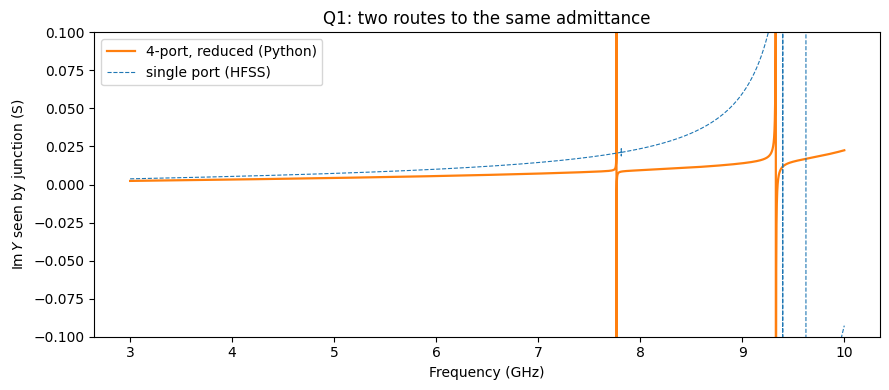

single-port modes (GHz): [3.3399 9.3966]
4-port reduced modes   : [4.1284 7.7705 9.3482]


In [ ]:
Y4_NPZ = BASE / "data/driven_modal/Y_junctions.npz"
if Y4_NPZ.exists():
    d4 = np.load(Y4_NPZ)
    f4, Y4 = d4["f"], d4["Y"]
    i = Q_DRIVE - 1
    o = [k for k in range(Y4.shape[1]) if k != i]
    w4 = 2 * np.pi * f4
    Y_load = np.stack([-1j / (w4 * LJ_NH[k] * 1e-9) for k in o], axis=-1)       # Lj only, no C_J
    Y_oo = Y4[:, o][:, :, o] + Y_load[:, :, None] * np.eye(len(o))
    x = np.linalg.solve(Y_oo, Y4[:, o, i][..., None])[..., 0]
    Y_red = Y4[:, i, i] - np.einsum("fk,fk->f", Y4[:, i, o], x)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(f4 / giga, Y_red.imag, color="tab:orange", lw=1.6, label="4-port, reduced (Python)")
    ax.plot(f_dm1 / giga, Y_dm1.imag, color="tab:blue", lw=0.8, ls="--", label="single port (HFSS)")
    ax.set_ylim(-0.1, 0.1)
    ax.set_xlabel("Frequency (GHz)")
    ax.set_ylabel(r"$\mathrm{Im}\,Y$ seen by junction (S)")
    ax.set_title(f"Q{Q_DRIVE}: two routes to the same admittance")
    ax.legend()
    fig.tight_layout()
    fig.savefig(BASE / "figures" / f"admittance_Q{Q_DRIVE}_1port_vs_4port.pdf")
    plt.show()

    bbq_red = BBQAnalysis(Y_red, f4, L_J1, C_J1)
    bbq_red.calculate_LCRZPhi(return_df=False)
    print("single-port modes (GHz):", np.round(bbq1.f_p / giga, 4))
    print("4-port reduced modes   :", np.round(bbq_red.f_p / giga, 4))
else:
    print("no 4-port Y_junctions.npz yet; run the next section first for this comparison")

# Driven Modal: all four junctions as ports


Same cavity and chips as `EM_Cavity_with_Transmons`, but each junction sheet is a **lumped port** `jj1..jj4`
(`JJ_PORT_Z` = 1 MΩ, as in the SNAIL notebook) instead of an inductor. The readout and drive bores keep their
50 Ω impedance boundaries, so cavity loss through the lines is included.

HFSS returns the **4×4 admittance matrix** Y(ω) between the junction ports. Y does not depend on the port
reference impedance, so the 1 MΩ value does not enter the result.

pybbq is single-port, so for qubit *i* the other three junctions are attached analytically as their linear
elements (L_J,k ∥ C_J):

$$Y_{\text{in},i} = Y_{ii} - Y_{io}\,\big(Y_{oo} + Y_{J,o}\big)^{-1}\,Y_{oi},\qquad o = \{k \neq i\}$$

This is the admittance junction *i* sees with the rest of the circuit in place. All four reductions describe the
same circuit, so they should find the **same mode frequencies**; what differs per junction is Φ_zpf (participation).
Changing `LJ_NH` / `CJ_BBQ_FF` only needs the BBQ cells, not a new HFSS solve.

In [ ]:
use_design("DM", "Modal")
ports = build_cavity()
JUNCTION_PORTS = add_transmons(junction="port")

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 8892!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to DM
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q.stp imported
PyAEDT INFO: Materials class has been initial

### Setup and sweeps
Adaptive mesh at `DM_FREQ`, then fast sweeps in `chunk`-wide pieces (as in the SNAIL notebook).
SNAIL used 0.1–10 GHz in 50 MHz chunks × 25 000 points (2 kHz step, one Y entry). With 4 ports there are
16 Y entries per point, so the default here is 3–10 GHz in 100 MHz chunks × 10 000 points (10 kHz step,
~110 MB of Y data). Tighten the step around a mode if its Q is not resolved.

In [ ]:
SETUP_DM = "DM"
DM_FREQ  = "4GHz"                                              # adaptive meshing frequency (SNAIL value)
DM_SWEEP = dict(start=3.0, stop=10.0, chunk=0.1, points=10_000)  # GHz, GHz, GHz, points per chunk

if SETUP_DM in hfss.get_setups():
    hfss.delete_setup(SETUP_DM)                                  # also removes its sweeps
hfss.create_setup(name=SETUP_DM,
                  SolveType="Single",
                  Frequency=DM_FREQ,
                  MaxDeltaS=0.01,
                  MaximumPasses=10,
                  MinimumPasses=3,
                  MinimumConvergedPasses=3,
                  PercentRefinement=30,
                  BasisOrder=-1,
                  DoLambdaRefine=True,
                  DoMaterialLambda=True,
                  SetLambdaTarget=False,
                  Target=0.3333,
                  UseMaxTetIncrease=False,
                  DrivenSolverType="Direct Solver",
                  EnhancedLowFreqAccuracy=False,
                  SaveRadFieldsOnly=False,
                  SaveAnyFields=True)

n_chunks = int(round((DM_SWEEP["stop"] - DM_SWEEP["start"]) / DM_SWEEP["chunk"]))
edges = np.linspace(DM_SWEEP["start"], DM_SWEEP["stop"], n_chunks + 1)
for k, (f0, f1) in enumerate(zip(edges, edges[1:])):
    hfss.create_linear_count_sweep(setup=SETUP_DM, units="GHz",
                                   start_frequency=round(float(f0), 6), stop_frequency=round(float(f1), 6),
                                   num_of_freq_points=DM_SWEEP["points"], name=f"Sweep_{k:03d}",
                                   save_fields=False, sweep_type="Fast")
print(f"[dm] {n_chunks} fast sweeps, {edges[0]:g}-{edges[-1]:g} GHz")

hfss.analyze(setup=SETUP_DM, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Key DrivenSolverType matched internal key 'SolveType' with confidence of 72.
PyAEDT INFO: Key EnhancedLowFreqAccuracy matched internal key 'PortAccuracy' with confidence of 56.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be 

True

### Junction Y matrix
Reads `Y(jji,jjj)` from every sweep (only i ≤ j: the network is reciprocal), drops the duplicated
chunk-edge points, and saves `data/driven_modal/Y_junctions.npz` (`f` in Hz, `Y` with shape `(Nf, 4, 4)` in S).

In [ ]:
Y_NPZ = BASE / "data/driven_modal/Y_junctions.npz"


def junction_y_matrix(setup=SETUP_DM):
    # Y(jji,jjj) from every sweep of `setup` -> (f [Hz], Y [Nf, n, n] in S).
    names = [f"jj{i}" for i in range(1, len(QUBIT_X) + 1)]
    n = len(names)
    pairs = [(i, j) for i in range(n) for j in range(i, n)]
    exprs = [f"Y({names[i]},{names[j]})" for i, j in pairs]
    f_all, Y_all = [], []
    for sweep in sorted(hfss.get_sweeps(setup)):
        data = hfss.post.get_solution_data(expressions=exprs, setup_sweep_name=f"{setup} : {sweep}")
        if not data:
            raise RuntimeError(f"no solution data for {setup} : {sweep} (not solved?)")
        f = None
        for (i, j), e in zip(pairs, exprs):
            x, re = data.get_expression_data(e, formula="real", convert_to_SI=True)
            _, im = data.get_expression_data(e, formula="imag", convert_to_SI=True)
            if f is None:
                f = np.asarray(x, dtype=float)
                Y = np.empty((len(f), n, n), dtype=complex)
            Y[:, i, j] = Y[:, j, i] = np.asarray(re) + 1j * np.asarray(im)
        f_all.append(f)
        Y_all.append(Y)
    f, Y = np.concatenate(f_all), np.concatenate(Y_all)
    f, keep = np.unique(f, return_index=True)          # sorted, without the shared chunk edges
    lo, hi = DM_SWEEP["start"] * giga, DM_SWEEP["stop"] * giga
    assert lo * 0.999 <= f[0] and f[-1] <= hi * 1.001, f"frequency axis {f[0]}..{f[-1]} is not in Hz"
    return f, Y[keep]


f_dm, Y_dm = junction_y_matrix()
np.savez(Y_NPZ, f=f_dm, Y=Y_dm, ports=[f"jj{i}" for i in range(1, len(QUBIT_X) + 1)])
print(f"[dm] Y matrix: {len(f_dm)} points, {f_dm[0] / giga:g}-{f_dm[-1] / giga:g} GHz -> {Y_NPZ.name}")

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: aedt file load time 0.6103301048278809
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.03911161422729492
Time to initialize solution data:0.21773433685302734
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.04064607620239258
Time to initialize solution data:0.22287535667419434
Py

### Black-box quantization (pybbq)
Runs from the saved `Y_junctions.npz`, so it works without HFSS open. One `BBQAnalysis` per junction, using
the reduced admittance above with `L_J = LJ_NH[i]` (**placeholders**) and `C_J = CJ_BBQ_FF`.
Each analysis' qubit mode is the one with the largest Φ_zpf at that junction. Cross-Kerr between qubits
is not part of this single-port BBQ; use the EPR section for that.

In [ ]:
from pybbq import BBQAnalysis


def junction_y(f, Lj, Cj=0.0):
    # Linear junction admittance: Lj in parallel with Cj (H, F).
    w = 2 * np.pi * f
    return 1j * w * Cj - 1j / (w * Lj)


def reduced_admittance(f, Y, i, Lj, Cj=0.0):
    # Admittance seen by junction port i with every other junction port k loaded by Lj[k] || Cj:
    # Y_in = Y_ii - Y_io (Y_oo + Y_J,o)^-1 Y_oi
    o = [k for k in range(Y.shape[1]) if k != i]
    Y_load = np.stack([junction_y(f, Lj[k], Cj) for k in o], axis=-1)       # (Nf, n-1)
    Y_oo = Y[:, o][:, :, o] + Y_load[:, :, None] * np.eye(len(o))
    x = np.linalg.solve(Y_oo, Y[:, o, i][..., None])[..., 0]
    return Y[:, i, i] - np.einsum("fk,fk->f", Y[:, i, o], x)


d = np.load(Y_NPZ)
f_dm, Y_dm = d["f"], d["Y"]
L_J = [l * 1e-9 for l in LJ_NH]
C_J = CJ_BBQ_FF * 1e-15

bbq, summary = {}, {}
for i in range(Y_dm.shape[1]):
    q = f"Q{i + 1}"
    bbq[q] = BBQAnalysis(reduced_admittance(f_dm, Y_dm, i, L_J, C_J), f_dm, L_J[i], C_J)
    bbq[q].calculate_LCRZPhi(return_df=False)
    bbq[q].save_BBOX_info(filename=BASE / "data/bbq" / f"bbq_results_{q}.csv")
    k = bbq[q].qindex
    summary[q] = {"L_J (nH)": LJ_NH[i], "f_q (GHz)": bbq[q].f_p[k] / giga, "Q": bbq[q].Q_p[k],
                  "Phi_zpf": bbq[q].Phi_p[k], "# modes found": len(bbq[q].f_p)}
summary = pd.DataFrame(summary).T
summary.to_csv(BASE / "data/bbq/bbq_summary.csv")

# consistency check: every reduction describes the same circuit, so the mode lists should agree
modes = {q: np.round(b.f_p / giga, 4) for q, b in bbq.items()}
if len({len(m) for m in modes.values()}) > 1:
    print("[bbq] warning: different number of modes per junction:", {q: len(m) for q, m in modes.items()})
summary

[bbq] warning: different number of modes per junction: {'Q1': 2, 'Q2': 2, 'Q3': 2, 'Q4': 1}


,L_J (nH),f_q (GHz),Q,Phi_zpf,# modes found
Q1,11.0,3.311501,225973.985204,0.318975,2.0
Q2,12.0,3.182348,241313.964052,0.327866,2.0
Q3,13.0,3.066847,256325.216814,0.336054,2.0
Q4,14.0,9.405071,91127.607758,0.000443,1.0


Mode Frequencies: [3.31150115 9.40507051] GHz
Mode Frequencies: [3.18234823 9.40507051] GHz
Mode Frequencies: [3.06684668 9.40507051] GHz
Mode Frequencies: [9.40507051] GHz


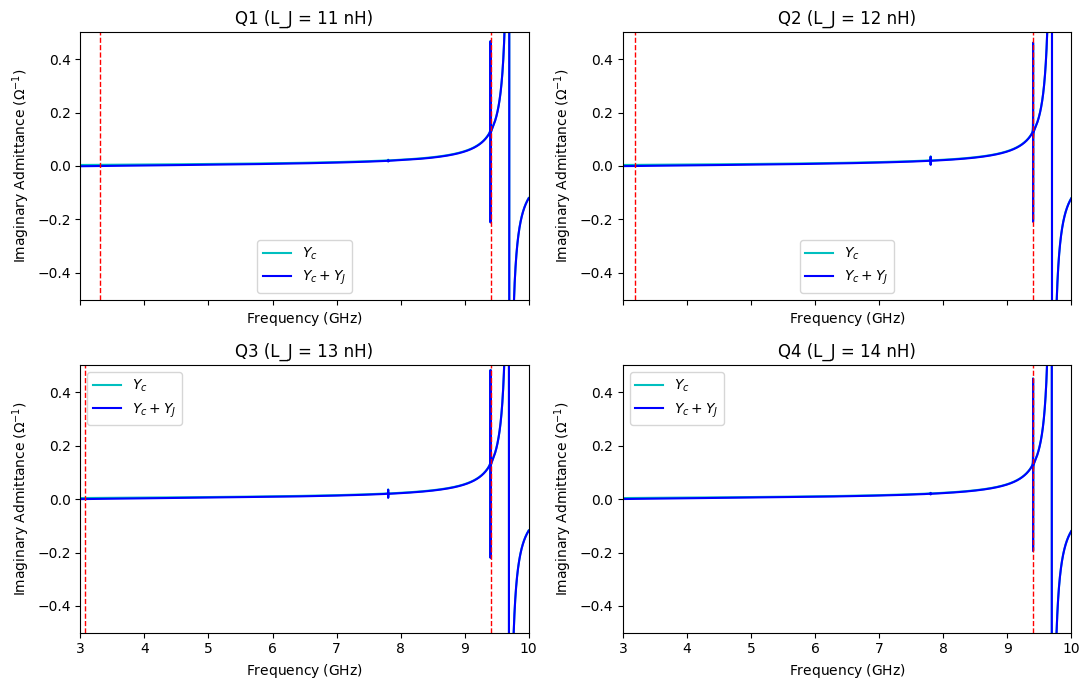

In [ ]:
# Im(Y) seen by each junction; dashed lines = modes (zero crossings of Im(Y_c + Y_J))
fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (q, b) in zip(axs.flat, bbq.items()):
    b.plot_admittances(fig=fig, ax=ax, ylim=[-0.5, 0.5])
    ax.set_title(f"{q} (L_J = {b.L_J * 1e9:g} nH)")
fig.tight_layout()
fig.savefig(BASE / "figures/admittances_junctions.pdf")
plt.show()

Coupling strengths: [0.         8.64929428] MHz
Coupling strengths: [0.         8.63956939] MHz
Coupling strengths: [0.         8.53847427] MHz
Coupling strengths: [0.] MHz


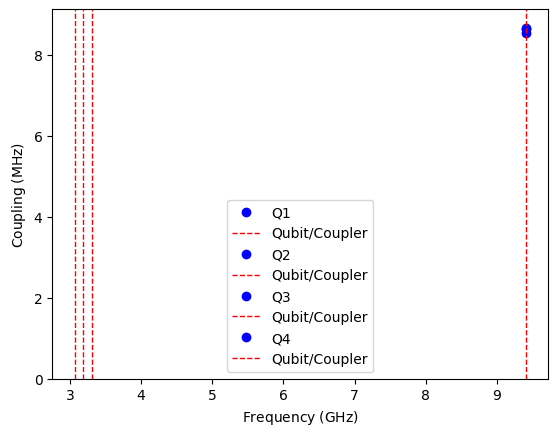

In [ ]:
# coupling of each qubit to the other modes
fig, ax = plt.subplots()
for q, b in bbq.items():
    b.plot_gs_vs_freq(fig=fig, ax=ax, label=q)
fig.savefig(BASE / "figures/gs_junctions.pdf")
plt.show()

# Save & Release HFSS

In [ ]:
hfss.save_project()

PyAEDT INFO: Project coffin_4Q Saved correctly


True

In [107]:
hfss.release_desktop(close_projects=False, close_desktop=False)   # leaves AEDT open

PyAEDT INFO: Desktop has been released.


True